<a href="https://colab.research.google.com/github/omdhasal27/AWS_AIML_Task1_Task2/blob/main/AWS_AIML_Task1_Task2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape of dataset: (250, 4)

Column types:
 area        int64
bedrooms    int64
age         int64
price       int64
dtype: object

First few rows:


,area,bedrooms,age,price
0,1660,4,15,11082502
1,2094,4,24,13399576
2,1930,3,7,12711003
3,1895,4,12,12771801
4,2438,4,20,15439023



Dataset description:


,area,bedrooms,age,price
count,250.000000,250.000000,250.000000,2.500000e+02
mean,2222.748000,2.568000,12.020000,1.400838e+07
std,739.358072,1.136019,7.203552,4.445813e+06
min,801.000000,1.000000,0.000000,5.086560e+06
25%,1597.250000,2.000000,6.000000,1.011394e+07
50%,2283.000000,3.000000,12.000000,1.414607e+07
75%,2840.250000,4.000000,18.000000,1.741489e+07
max,3495.000000,4.000000,24.000000,2.179285e+07



Missing values before fixing:
 area        12
bedrooms    12
age         16
price       20
dtype: int64

Missing values after fixing:
 area        0
bedrooms    0
age         0
price       0
dtype: int64

Mean price: ₹ 14042790.99
Median price: ₹ 14146066.0
Standard deviation of price: ₹ 4319719.45
Minimum price: ₹ 5086560.0
Maximum price: ₹ 21792846.0

Correlation matrix:
               area  bedrooms     price
area      1.000000 -0.022745  0.943786
bedrooms -0.022745  1.000000  0.064585
price     0.943786  0.064585  1.000000

Average price per number of bedrooms:
bedrooms
1.0    1.358184e+07
2.0    1.360013e+07
3.0    1.485316e+07
4.0    1.404902e+07
Name: price, dtype: float64


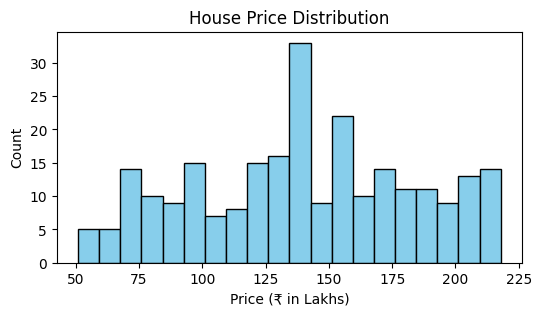

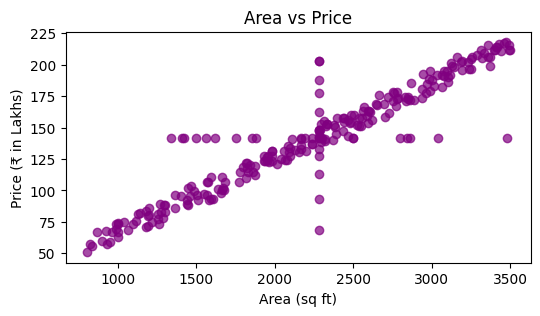

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# generating synthetic dataset for 250 houses in INR
np.random.seed(42)
n = 250

area = np.random.randint(800, 3500, n)
bedrooms = np.random.randint(1, 5, n)
age = np.random.randint(0, 25, n)
# price in Indian Rupees (₹)
price = area * 6000 + bedrooms * 400000 - age * 30000 + np.random.randint(-200000, 200000, n)

df = pd.DataFrame({
    'area': area,
    'bedrooms': bedrooms,
    'age': age,
    'price': price
})

# inspect data
print("Shape of dataset:", df.shape)
print("\nColumn types:\n", df.dtypes)
print("\nFirst few rows:")
display(df.head())
print("\nDataset description:")
display(df.describe())

# removing about 5% of values at random to simulate missing data
np.random.seed(10)
mask = np.random.rand(*df.shape) < 0.05
df_missing = df.copy()
df_missing[mask] = np.nan

print("\nMissing values before fixing:\n", df_missing.isnull().sum())

# fill missing values using median because it is less affected by outliers
df_clean = df_missing.fillna(df_missing.median())
print("\nMissing values after fixing:\n", df_clean.isnull().sum())

# numpy operations
prices_arr = df_clean['price'].to_numpy()
area_arr = df_clean['area'].to_numpy()
df_clean['price_per_sqft'] = prices_arr / area_arr

# basic statistics
print("\nMean price: ₹", round(df_clean['price'].mean(), 2))
print("Median price: ₹", round(df_clean['price'].median(), 2))
print("Standard deviation of price: ₹", round(df_clean['price'].std(), 2))
print("Minimum price: ₹", df_clean['price'].min())
print("Maximum price: ₹", df_clean['price'].max())

print("\nCorrelation matrix:\n", df_clean[['area', 'bedrooms', 'price']].corr())

# groupby operation
print("\nAverage price per number of bedrooms:")
print(df_clean.groupby('bedrooms')['price'].mean())

# bonus plots (plotting price in Lakhs for better readability)
plt.figure(figsize=(6, 3))
plt.hist(df_clean['price'] / 100000, bins=20, color='skyblue', edgecolor='black')
plt.title('House Price Distribution')
plt.xlabel('Price (₹ in Lakhs)')
plt.ylabel('Count')
plt.show()

plt.figure(figsize=(6, 3))
plt.scatter(df_clean['area'], df_clean['price'] / 100000, alpha=0.7, color='purple')
plt.title('Area vs Price')
plt.xlabel('Area (sq ft)')
plt.ylabel('Price (₹ in Lakhs)')
plt.show()

### Observations:
1. **Area impact**: Area has the strongest positive correlation with the house price compared to other features.
2. **Bedrooms**: Most houses in the dataset feature between 2 and 3 bedrooms.
3. **Missing Data**: Missing values were filled using the median because it prevents outliers from skewing the filled data.
4. **Distribution**: The price distribution histogram shows that most houses are priced moderately with very few extreme high-end properties.

Intercept: ₹ 368864.89
Coefficients (Area, Bedrooms): [  5691.02173243 391597.28589365]

Model Evaluation:
MAE: ₹ 836400.48
RMSE: ₹ 1596480.68
R2 Score: 0.8527

Predicted price for 1,200 sq ft and 3 bedrooms: ₹8,372,882.83


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


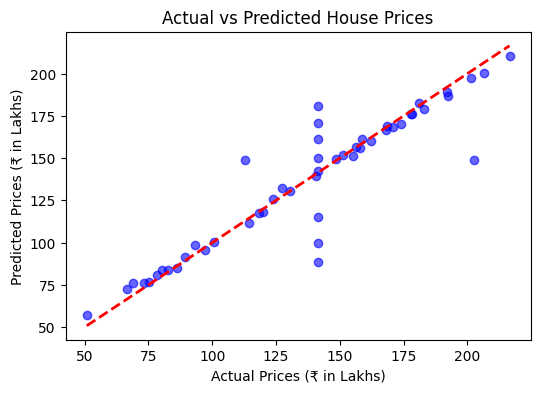

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# prepare features and target
X = df_clean[['area', 'bedrooms']]
y = df_clean['price']

# split into training and testing sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# train model
model = LinearRegression()
model.fit(X_train, y_train)

# interpret coefficients and intercept
print("Intercept: ₹", round(model.intercept_, 2))
print("Coefficients (Area, Bedrooms):", model.coef_)

# evaluate model
y_pred = model.predict(X_test)
print("\nModel Evaluation:")
print("MAE: ₹", round(mean_absolute_error(y_test, y_pred), 2))
print("RMSE: ₹", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))

# predict a new house (e.g., 1200 sq ft, 3 bedrooms)
new_house = [[1200, 3]]
predicted_price = model.predict(new_house)
print(f"\nPredicted price for 1,200 sq ft and 3 bedrooms: ₹{predicted_price[0]:,.2f}")

# visualize actual vs predicted prices (in Lakhs)
plt.figure(figsize=(6, 4))
plt.scatter(y_test / 100000, y_pred / 100000, color='blue', alpha=0.6)
plt.plot([y_test.min() / 100000, y_test.max() / 100000], [y_test.min() / 100000, y_test.max() / 100000], 'r--', lw=2)
plt.xlabel('Actual Prices (₹ in Lakhs)')
plt.ylabel('Predicted Prices (₹ in Lakhs)')
plt.title('Actual vs Predicted House Prices')
plt.show()